In [15]:
import pickle
file_path1 = "dp_infos1.pkl"
file_path2 = "dp_infos4.pkl"
file_path3 = "dp_infos.pkl"

with open(file_path3, 'rb') as file:
    data1 = pickle.load(file)

with open(file_path2, 'rb') as file:
    data2 = pickle.load(file)


# with open(file_path3, 'rb') as file:
#     data = pickle.load(file)


In [16]:
def merge_data(data1, data2, keys_to_remove):
    # data1에서 특정 키 제거
    for key in keys_to_remove:
        if key in data1:
            del data1[key]
    
    # data2를 data1에 병합
    data1.update(data2)
    
    return data1

# 사용 예시
keys_to_remove = ['rzj4FFi7wt8']

data = merge_data(data1, data2, keys_to_remove)

In [17]:
data

{'MfO1FenJbKI': [{30: {'dp': [(8, 16), (62, 70), (409, 420)],
    'reward_sum': 24.038545934205338},
   45: {'dp': [(0, 4), (9, 17), (62, 70), (103, 110), (408, 421)],
    'reward_sum': 34.459759948804766},
   60: {'dp': [(0, 17), (61, 71), (102, 110), (304, 311), (408, 421)],
    'reward_sum': 43.86796826623228},
   75: {'dp': [(0, 19),
     (60, 71),
     (102, 110),
     (227, 235),
     (303, 311),
     (407, 422)],
    'reward_sum': 53.01153670370685},
   90: {'dp': [(0, 21),
     (60, 72),
     (101, 111),
     (198, 205),
     (227, 236),
     (303, 311),
     (407, 423)],
    'reward_sum': 61.58722113150026},
   105: {'dp': [(0, 23),
     (59, 73),
     (99, 111),
     (198, 206),
     (225, 237),
     (302, 313),
     (406, 424)],
    'reward_sum': 69.69354228559476},
   120: {'dp': [(0, 29),
     (58, 74),
     (98, 112),
     (198, 206),
     (223, 238),
     (301, 313),
     (406, 425)],
    'reward_sum': 77.2638400871942},
   135: {'dp': [(0, 29),
     (57, 75),
     (96, 

In [11]:
data

[[0.8012848644735112,
  0.743464664788879,
  0.8910619353896074,
  0.8324488907061787,
  0.6847698643137649],
 [0.7657724433067726,
  0.7002179006919653,
  0.8356732971008574,
  0.7879403156501501,
  0.6092928964601025],
 [0.7311328044372047,
  0.6512694415965349,
  0.789186876324418,
  0.7391485903635572,
  0.5568444744927491],
 [0.706820489382758,
  0.614833456223069,
  0.750165023034971,
  0.6937604297926699,
  0.5117557632009431],
 [0.6843024570166695,
  0.5830525695312824,
  0.7166950108349749,
  0.6548548805965563,
  0.4762590265330665],
 [0.6637480217675691,
  0.5564885405483941,
  0.6837585295228217,
  0.6293171755322089,
  0.44822668488391243],
 [0.6438653340599516,
  0.5341516801032505,
  0.6528328044149893,
  0.6026442970834643,
  0.42489501624838855]]

In [4]:
shot_cnt = {}
shot_dur = {}
MRD_average = {}

In [5]:
def calculate_average_duration(gap):
    cnt = []
    for elem in gap:
        a, b = elem
        c = b - a + 1
        cnt.append(c)
    return sum(cnt)/len(cnt)

In [6]:
shot_cnt = [[] for _ in range(7)]  # 30, 60, 90, 120초에 해당하는 리스트 생성
shot_dur = [[] for _ in range(7)]  # 30, 60, 90, 120초에 해당하는 리스트 생성
MRD_average = [[] for _ in range(7)]  # 30, 60, 90, 120초에 해당하는 리스트 생성
seconds = [30, 45, 60, 75, 90, 105, 120,]

for video_id in data.keys():
    for i, sec in enumerate(seconds):
        dp = data[video_id][0][sec]['dp']
        reward_sum = data[video_id][0][sec]['reward_sum']
        dur = calculate_average_duration(dp)
        # print(i)
        shot_cnt[i].append(len(dp))
        shot_dur[i].append(dur)
        MRD_average[i].append(reward_sum/sec)

In [7]:
shot_cnt

[[3, 3, 3, 3, 3],
 [5, 4, 4, 4, 4],
 [5, 5, 5, 4, 4],
 [6, 5, 6, 5, 5],
 [7, 7, 6, 6, 6],
 [7, 8, 6, 8, 7],
 [7, 8, 7, 10, 7]]

In [8]:
shot_dur

[[10.0, 10.0, 10.0, 10.0, 10.0],
 [9.0, 11.25, 11.25, 11.25, 11.25],
 [12.0, 12.0, 12.0, 15.0, 15.0],
 [12.5, 15.0, 12.5, 15.0, 15.0],
 [12.857142857142858, 12.857142857142858, 15.0, 15.0, 15.0],
 [15.0, 13.125, 17.5, 13.125, 15.0],
 [17.142857142857142, 15.0, 17.142857142857142, 12.0, 17.142857142857142]]

In [9]:
MRD_average

[[0.8012848644735112,
  0.743464664788879,
  0.8910619353896074,
  0.8324488907061787,
  0.6847698643137649],
 [0.7657724433067726,
  0.7002179006919653,
  0.8356732971008574,
  0.7879403156501501,
  0.6092928964601025],
 [0.7311328044372047,
  0.6512694415965349,
  0.789186876324418,
  0.7391485903635572,
  0.5568444744927491],
 [0.706820489382758,
  0.614833456223069,
  0.750165023034971,
  0.6937604297926699,
  0.5117557632009431],
 [0.6843024570166695,
  0.5830525695312824,
  0.7166950108349749,
  0.6548548805965563,
  0.4762590265330665],
 [0.6637480217675691,
  0.5564885405483941,
  0.6837585295228217,
  0.6293171755322089,
  0.44822668488391243],
 [0.6438653340599516,
  0.5341516801032505,
  0.6528328044149893,
  0.6026442970834643,
  0.42489501624838855]]

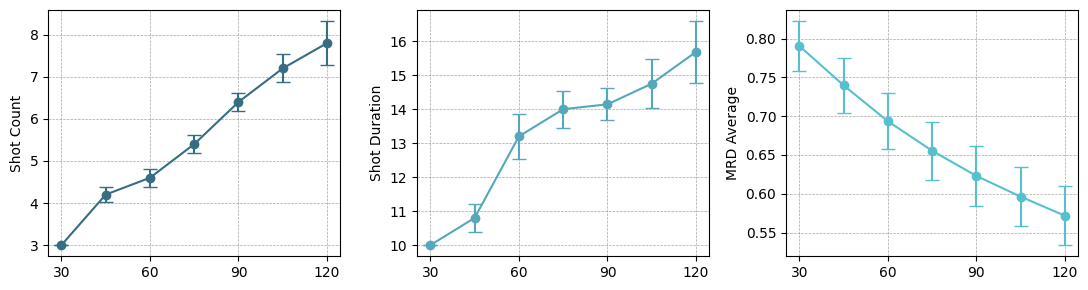

In [10]:
import matplotlib.pyplot as plt
import numpy as np
time_points = [30, 45, 60, 75, 90, 105, 120,]

data_sets = [shot_cnt, shot_dur, MRD_average]
titles = ['Shot Count', 'Shot Duration', 'MRD Average']
colors = ['#366D83', '#55A7BC', '#55C0CF']  # Colors for each subplot

fig, axs = plt.subplots(1, 3, figsize=(11, 3))

# fig.suptitle('Data Visualization with Error Bars')

for i, (data, title) in enumerate(zip(data_sets, titles)):
    means = [np.mean(d) for d in data]
    stds = [np.std(d) / np.sqrt(len(d)) for d in data]  # standard error of the mean
    
    axs[i].errorbar(time_points, means, yerr=stds, fmt='-o', capsize=5, color=colors[i])
    # axs[i].set_xlabel('Time (seconds)')
    axs[i].set_ylabel(title)
    
    axs[i].set_xticks([30, 60, 90, 120])  # Set x-ticks to 30, 60, 90, 120
    axs[i].set_xticklabels([30, 60, 90, 120])
    
    # Remove the grid
    axs[i].grid(True,  color='gray', linestyle='--', linewidth=0.5, alpha=0.7, zorder=0)

plt.tight_layout()
plt.show()
